# Computational Lab 2 — Particle current, Fick's law, and continuity

In Lab 1, flux was inferred from a smooth density gradient. Here we measure
particle current microscopically by counting signed crossings of cell faces.
We then test whether the counted current agrees with Fick's law and whether it
satisfies local conservation.

**Learning goals**

1. interpret particle flux as a signed crossing rate;
2. test the constitutive relation $J=-D\,\partial_x n$;
3. verify the continuity equation cell by cell; and
4. distinguish particle current from electrical current.

Lengths are in micrometres and times in seconds. The one-dimensional model has
unit cross-sectional area.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "lecture-notes" / "main.tex").exists()
)
OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})

## 1. Finite-volume random walk

Cell $i$ contains $N_i$ particles and has width $\Delta x$. During one time
step each particle jumps left with probability $r$, right with probability
$r$, or stays put. Matching this lattice walk to diffusion gives

\[
    r=\frac{D\Delta t}{\Delta x^2}, \qquad 2r\leq 1.
\]

Let $R_i$ be right-going jumps from cell $i$ and $L_{i+1}$ left-going jumps
from its neighbour. The directly measured current through their common face is

\[
    J_{i+1/2}^{\rm count}=\frac{R_i-L_{i+1}}{\Delta t}.
\]

Since $n_i=N_i/\Delta x$, its conditional mean is exactly the discrete Fick
law

\[
    \mathbb E[J_{i+1/2}^{\rm count}\mid N]
    =-D\frac{n_{i+1}-n_i}{\Delta x}.
\]

In [2]:
rng = np.random.default_rng(62713)
diffusivity = 0.50              # micrometre^2 / s
domain_length = 20.0            # micrometre
cell_count = 80
spacing = domain_length / cell_count
time_step = 0.020                # s
final_time = 4.0                 # s
step_count = round(final_time / time_step)
time = time_step * np.arange(step_count + 1)
jump_probability = diffusivity * time_step / spacing**2

assert 2.0 * jump_probability <= 1.0
coordinate = -domain_length / 2.0 + spacing * (0.5 + np.arange(cell_count))
face_coordinate = -domain_length / 2.0 + spacing * (1.0 + np.arange(cell_count))

# A high-density left half and low-density right half create a positive
# diffusive current through the central face. Periodicity creates a second,
# oppositely oriented interface at the domain edge.
counts = np.where(coordinate < 0.0, 40_000, 10_000).astype(np.int64)
initial_total = int(np.sum(counts))
center_face = cell_count // 2 - 1
sample_times = np.array([0.0, 0.20, 1.00, 4.00])
sample_steps = {round(value / time_step): value for value in sample_times}
density_snapshots = {0.0: counts / spacing}

measured_current = np.zeros((step_count, cell_count))
fick_current = np.zeros((step_count, cell_count))
maximum_continuity_residual = np.zeros(step_count)
total_particles = np.zeros(step_count + 1, dtype=np.int64)
total_particles[0] = initial_total

for step in range(step_count):
    old_density = counts / spacing
    split = np.array([
        rng.multinomial(int(number), [jump_probability, jump_probability, 1.0 - 2.0 * jump_probability])
        for number in counts
    ])
    left_jump = split[:, 0]
    right_jump = split[:, 1]

    # Face i lies between cells i and i+1; positive current points right.
    measured_current[step] = (
        right_jump - np.roll(left_jump, -1)
    ) / time_step
    fick_current[step] = -diffusivity * (
        np.roll(old_density, -1) - old_density
    ) / spacing

    counts += (
        np.roll(right_jump, 1) + np.roll(left_jump, -1)
        - right_jump - left_jump
    )
    new_density = counts / spacing
    divergence = (
        measured_current[step] - np.roll(measured_current[step], 1)
    ) / spacing
    continuity_residual = (new_density - old_density) / time_step + divergence
    maximum_continuity_residual[step] = np.max(np.abs(continuity_residual))
    total_particles[step + 1] = np.sum(counts)

    completed_step = step + 1
    if completed_step in sample_steps:
        density_snapshots[sample_steps[completed_step]] = new_density.copy()

## 2. Verification

Three different checks answer three different questions:

- exact total count tests global conservation;
- the continuity residual tests local bookkeeping;
- a regression of counted current on Fick current tests the constitutive law.

An individual crossing count is noisy. Agreement is expected statistically,
not at every face and every time step.

In [3]:
flat_counted = measured_current.ravel()
flat_fick = fick_current.ravel()
fick_slope = np.dot(flat_fick, flat_counted) / np.dot(flat_fick, flat_fick)
fick_correlation = np.corrcoef(flat_fick, flat_counted)[0, 1]

assert np.all(total_particles == initial_total)
assert np.max(maximum_continuity_residual) < 1.0e-9
assert np.isclose(fick_slope, 1.0, rtol=0.08)

print(f"jump probability r          = {jump_probability:.3f}")
print(f"total particles             = {initial_total:,d} (exactly conserved)")
print(f"largest continuity residual = {np.max(maximum_continuity_residual):.3e}")
print(f"counted-vs-Fick slope        = {fick_slope:.4f}")
print(f"counted-vs-Fick correlation  = {fick_correlation:.4f}")

jump probability r          = 0.160
total particles             = 2,000,000 (exactly conserved)
largest continuity residual = 0.000e+00
counted-vs-Fick slope        = 1.0076
counted-vs-Fick correlation  = 0.9289


## 3. Current through one face

The cumulative signed crossing count is the time integral of particle current.
A short moving average makes the instantaneous stochastic current readable,
without altering the simulation or the quantitative tests above.

In [4]:
center_counted = measured_current[:, center_face]
center_fick = fick_current[:, center_face]
window = 11
smoothing_kernel = np.ones(window) / window
smoothed_center_counted = np.convolve(center_counted, smoothing_kernel, mode="valid")
smoothed_time = time[1:][window - 1:]

cumulative_counted = np.cumsum(center_counted) * time_step
cumulative_fick = np.cumsum(center_fick) * time_step

# Convert particle current to conventional electrical current. For electrons,
# q=-e, so conventional current points opposite to electron particle flux.
elementary_charge = 1.602_176_634e-19   # coulomb
electron_current_ampere = -elementary_charge * center_counted
print(
    "initial electron conventional current through center face = "
    f"{electron_current_ampere[0]:+.3e} A"
)

initial electron conventional current through center face = -3.833e-14 A


## 4. Results

The density step relaxes, the central particle current decays as the gradient
weakens, and accumulated signed crossings follow the time integral predicted
by Fick's law. The continuity residual is at roundoff because the measured face
currents account for every particle entering or leaving each cell.

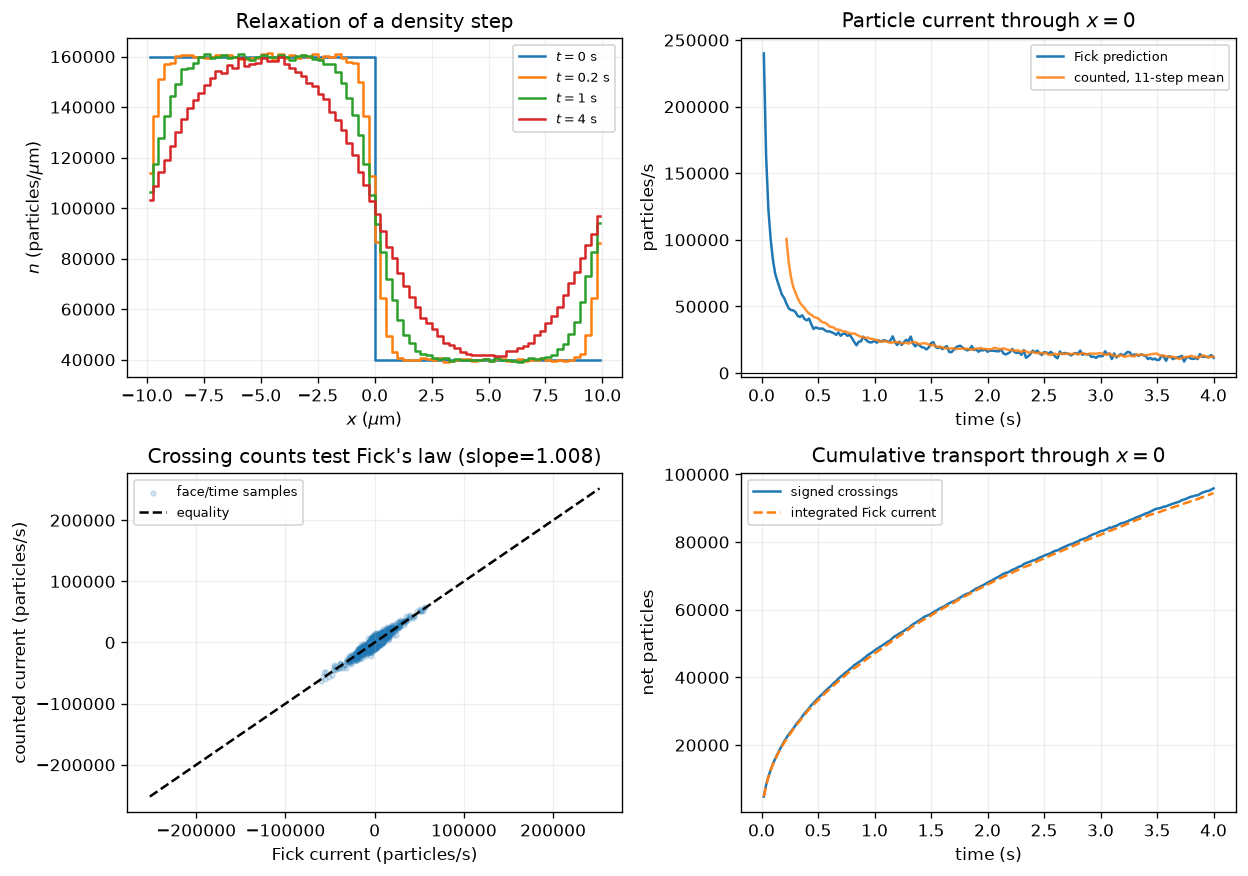

wrote lecture-notes/figures/08_brownian-motion-diffusion/lab-02-particle-current.pdf


In [5]:
figure, axes = plt.subplots(2, 2, figsize=(10.5, 7.4))

for sample_time in sample_times:
    axes[0, 0].step(
        coordinate,
        density_snapshots[sample_time],
        where="mid",
        label=rf"$t={sample_time:g}$ s",
    )
axes[0, 0].set(title="Relaxation of a density step", xlabel=r"$x$ ($\mu$m)", ylabel=r"$n$ (particles/$\mu$m)")
axes[0, 0].legend(fontsize=8)

axes[0, 1].plot(time[1:], center_fick, label="Fick prediction", linewidth=1.5)
axes[0, 1].plot(smoothed_time, smoothed_center_counted, label=f"counted, {window}-step mean", alpha=0.85)
axes[0, 1].axhline(0.0, color="black", linewidth=0.7)
axes[0, 1].set(title="Particle current through $x=0$", xlabel="time (s)", ylabel="particles/s")
axes[0, 1].legend(fontsize=8)

sample_stride = 8
axes[1, 0].scatter(flat_fick[::sample_stride], flat_counted[::sample_stride], s=8, alpha=0.18, label="face/time samples")
current_limit = 1.05 * np.max(np.abs(flat_fick))
axes[1, 0].plot([-current_limit, current_limit], [-current_limit, current_limit], "--", color="black", label="equality")
axes[1, 0].set(title=rf"Crossing counts test Fick's law (slope={fick_slope:.3f})", xlabel="Fick current (particles/s)", ylabel="counted current (particles/s)")
axes[1, 0].legend(fontsize=8)

axes[1, 1].plot(time[1:], cumulative_counted, label="signed crossings")
axes[1, 1].plot(time[1:], cumulative_fick, "--", label="integrated Fick current")
axes[1, 1].set(title="Cumulative transport through $x=0$", xlabel="time (s)", ylabel="net particles")
axes[1, 1].legend(fontsize=8)

for axis in axes.flat:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "lab-02-particle-current.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": "DLSU SEMPHY01", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")

## Questions and extensions

1. Why does the central current start positive? Explain its later decay using
   the density graph and Fick's law.
2. Divide the initial cell populations by 10. Which quantities become noisier?
   Does exact local conservation survive?
3. Change `time_step` so that $2r>1$. Why is that invalid for this random-walk
   algorithm, and how is it related to the explicit diffusion stability limit?
4. Replace the equal left/right probabilities by a small bias. Show that the
   continuum constitutive law becomes $J=vn-D\partial_x n$.
5. For holes with charge $+e$ and electrons with charge $-e$, compare particle
   flux direction with conventional-current direction.